Training CSV: /content/drive/MyDrive/Colab Notebooks/MLA/dataset/persuade_corpus_2.0_train.csv
Test CSV: /content/drive/MyDrive/Colab Notebooks/MLA/dataset/persuade_corpus_2.0_test.csv

Raw data shapes:
  train_raw: (173266, 11)
  test_raw:  (112117, 11)

After removing unlabeled/empty discourse rows:
  train labeled rows: 144,289
  train labeled essays: 15,593
Training Label Distribution


,count
discourse_effectiveness,
Ineffective,6462
Adequate,113244
Effective,24583


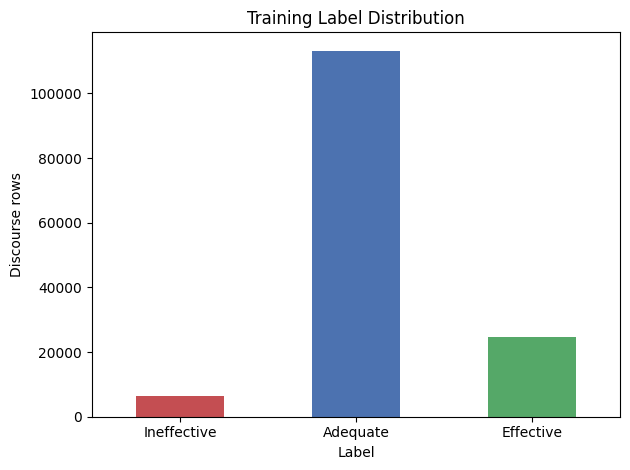


Split summary:


,total_test_csv_essays,validation_essays,test_essays,unused_test_csv_essays,split_method
0,10402,5201,5201,0,half_by_essay_id



Training plan_a_tfidf_logistic_regression_C2...
Validation metrics for plan_a_tfidf_logistic_regression_C2:
  accuracy: 0.0613
  macro_f1: 0.0477
  weighted_f1: 0.0521
  ineffective_recall: 0.7399
  quadratic_weighted_kappa: 0.0122
  fit_seconds: 431.3165

Training plan_b_tfidf_linear_svm_C1...
Validation metrics for plan_b_tfidf_linear_svm_C1:
  accuracy: 0.7825
  macro_f1: 0.4986
  weighted_f1: 0.7740
  ineffective_recall: 0.1592
  quadratic_weighted_kappa: 0.3217
  fit_seconds: 1050.4117

Training tuned_linear_svm_C0_5...
Validation metrics for tuned_linear_svm_C0_5:
  accuracy: 0.7920
  macro_f1: 0.5101
  weighted_f1: 0.7821
  ineffective_recall: 0.1655
  quadratic_weighted_kappa: 0.3406
  fit_seconds: 1088.2130

Training tuned_linear_svm_C1...
Validation metrics for tuned_linear_svm_C1:
  accuracy: 0.7825
  macro_f1: 0.4986
  weighted_f1: 0.7740
  ineffective_recall: 0.1592
  quadratic_weighted_kappa: 0.3217
  fit_seconds: 1010.7978

Training tuned_linear_svm_C2...
Validation met

,predicted_Ineffective,predicted_Adequate,predicted_Effective
actual_Ineffective,354,1580,92
actual_Adequate,857,33546,3151
actual_Effective,58,4154,3064



Saved outputs:
  Metrics: /content/discourse_effectiveness_outputs/metrics.json
  Classification report: /content/discourse_effectiveness_outputs/classification_report_test.txt
  Confusion matrix: /content/discourse_effectiveness_outputs/confusion_matrix_test.csv
  Model: /content/discourse_effectiveness_outputs/best_discourse_effectiveness_model.joblib
  Grouped Teacher-support predictions: /content/discourse_effectiveness_outputs/teacher_support_predictions_test.csv


In [ ]:
# Discourse Effectiveness Prediction for Teacher Support in Student Argumentative Writing
# Single-file Google Colab version.
#
# This is a no-deep-learning classical ML pipeline based on nodl.txt.

from __future__ import annotations

import inspect
import json
import re
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=ConvergenceWarning)


# =========================
# Configuration
# =========================

RANDOM_SEED = 42
ACCURACY_TARGET = 0.75
MAX_TFIDF_FEATURES = 160_000
RUN_HYPERPARAMETER_TUNING = True
USE_CLASS_WEIGHT_BALANCED = True
INEFFECTIVE_BOOST_THRESHOLD = 0.20  # Custom probability threshold for predicting 'Ineffective'

# Default Colab output location.
OUTPUT_DIR = Path("/content/discourse_effectiveness_outputs")
MODEL_PATH = OUTPUT_DIR / "best_discourse_effectiveness_model.joblib"

# Updated paths pointing to your Google Drive directory.
TRAIN_CSV_CANDIDATES = [
    Path("/content/drive/MyDrive/Colab Notebooks/MLA/dataset/persuade_corpus_2.0_train.csv"),
    Path("/content/drive/MyDrive/Colab Notebooks/MLA/dataset/train.csv"),
    Path("/content/persuade_corpus_2.0_train.csv"),
    Path("persuade_corpus_2.0_train.csv"),
]

TEST_CSV_CANDIDATES = [
    Path("/content/drive/MyDrive/Colab Notebooks/MLA/dataset/persuade_corpus_2.0_test.csv"),
    Path("/content/drive/MyDrive/Colab Notebooks/MLA/dataset/test.csv"),
    Path("/content/persuade_corpus_2.0_test.csv"),
    Path("persuade_corpus_2.0_test.csv"),
]

# Split test CSV in half for validation and testing.
SPLIT_TEST_CSV_EXACTLY_IN_HALF = True

FIXED_VALIDATION_ESSAYS = 5000
FIXED_TEST_ESSAYS = 5000

LABEL_ORDER = ["Ineffective", "Adequate", "Effective"]
LABEL_TO_SCORE = {label: index for index, label in enumerate(LABEL_ORDER)}

TARGET_COLUMN = "discourse_effectiveness"
GROUP_COLUMN = "essay_id"
TEXT_COLUMN = "discourse_text"

ID_COLUMNS = ["essay_id", "essay_id_comp", "discourse_id"]
RAW_FEATURE_COLUMNS = [
    "discourse_text",
    "discourse_type",
    "discourse_type_num",
    "prompt_name",
    "discourse_start",
    "discourse_end",
    "essay_word_count",
]
CATEGORICAL_FEATURES = ["discourse_type", "discourse_type_num", "prompt_name"]
NUMERIC_FEATURES = [
    "discourse_start_num",
    "discourse_end_num",
    "essay_word_count_num",
    "discourse_char_count",
    "discourse_word_count",
    "discourse_fraction_of_essay",
]
MODEL_FEATURES = [TEXT_COLUMN, *CATEGORICAL_FEATURES, *NUMERIC_FEATURES]
USE_COLUMNS = sorted(set(ID_COLUMNS + RAW_FEATURE_COLUMNS + [TARGET_COLUMN]))


# =========================
# Helper Functions
# =========================

def find_existing_path(candidates: list[Path]) -> Path | None:
    for path in candidates:
        if path.exists():
            return path
    return None


def running_in_colab() -> bool:
    try:
        import google.colab  # type: ignore  # noqa: F401

        return True
    except Exception:
        return False


def upload_missing_files_if_needed() -> None:
    if not running_in_colab():
        return

    train_path = find_existing_path(TRAIN_CSV_CANDIDATES)
    test_path = find_existing_path(TEST_CSV_CANDIDATES)
    if train_path is not None and test_path is not None:
        return

    try:
        print("Google Drive datasets not detected at direct paths. Attempting to mount Google Drive...")
        from google.colab import drive
        drive.mount('/content/drive')
        train_path = find_existing_path(TRAIN_CSV_CANDIDATES)
        test_path = find_existing_path(TEST_CSV_CANDIDATES)
        if train_path is not None and test_path is not None:
            return
    except Exception as e:
        print(f"Could not automatically mount Google Drive: {e}")

    print("CSV files were not found. Upload the train and test CSV files now.")
    from google.colab import files  # type: ignore

    files.upload()


def read_persuade_csv(path: Path) -> pd.DataFrame:
    string_columns = {
        "essay_id",
        "essay_id_comp",
        "discourse_id",
        "discourse_text",
        "discourse_type",
        "discourse_type_num",
        "prompt_name",
        "discourse_effectiveness",
    }
    dtype = {column: "string" for column in string_columns}

    return pd.read_csv(
        path,
        usecols=lambda column: column in USE_COLUMNS,
        dtype=dtype,
        low_memory=False,
    )


def clean_text(value: object) -> str:
    text = "" if pd.isna(value) else str(value)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def clean_labeled_rows(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df[TARGET_COLUMN] = df[TARGET_COLUMN].astype("string")
    df = df[df[TARGET_COLUMN].isin(LABEL_ORDER)]
    df[TEXT_COLUMN] = df[TEXT_COLUMN].map(clean_text)
    df = df[df[TEXT_COLUMN].ne("")]
    return df.reset_index(drop=True)


def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    df[TEXT_COLUMN] = df[TEXT_COLUMN].map(clean_text)
    for column in CATEGORICAL_FEATURES:
        if column not in df.columns:
            df[column] = "Unknown"
        df[column] = df[column].fillna("Unknown").astype(str)

    text = df[TEXT_COLUMN].astype(str)
    df["discourse_char_count"] = text.str.len().astype(float)
    df["discourse_word_count"] = text.str.split().str.len().astype(float)

    for raw_column, numeric_column in [
        ("discourse_start", "discourse_start_num"),
        ("discourse_end", "discourse_end_num"),
        ("essay_word_count", "essay_word_count_num"),
    ]:
        if raw_column not in df.columns:
            df[raw_column] = np.nan
        df[numeric_column] = pd.to_numeric(df[raw_column], errors="coerce")

    essay_words = df["essay_word_count_num"].replace(0, np.nan)
    df["discourse_fraction_of_essay"] = (
        df["discourse_word_count"] / essay_words
    ).replace([np.inf, -np.inf], np.nan)

    for column in NUMERIC_FEATURES:
        df[column] = df[column].fillna(0.0).astype(float)

    return df


def prepare_labeled_frame(df: pd.DataFrame) -> pd.DataFrame:
    return add_engineered_features(clean_labeled_rows(df))


def get_xy(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    return df[MODEL_FEATURES], df[TARGET_COLUMN].astype(str)


def make_one_hot_encoder() -> OneHotEncoder:
    params = inspect.signature(OneHotEncoder).parameters
    if "sparse_output" in params:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    return OneHotEncoder(handle_unknown="ignore", sparse=True)


def build_preprocessor(max_features: int = MAX_TFIDF_FEATURES) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            (
                "text",
                TfidfVectorizer(
                    lowercase=True,
                    strip_accents="unicode",
                    ngram_range=(1, 2),
                    min_df=2,
                    max_features=max_features,
                    sublinear_tf=True,
                ),
                TEXT_COLUMN,
            ),
            ("categorical", make_one_hot_encoder(), CATEGORICAL_FEATURES),
            ("numeric", StandardScaler(with_mean=False), NUMERIC_FEATURES),
        ],
        sparse_threshold=0.3,
    )


def build_logistic_regression_model(c: float = 2.0) -> Pipeline:
    weight = "balanced" if USE_CLASS_WEIGHT_BALANCED else None
    return Pipeline(
        steps=[
            ("features", build_preprocessor()),
            (
                "classifier",
                LogisticRegression(
                    C=c,
                    max_iter=500,
                    solver="saga",
                    random_state=RANDOM_SEED,
                    class_weight=weight
                ),
            ),
        ]
    )


def build_linear_svm_model(c: float = 1.0) -> Pipeline:
    weight = "balanced" if USE_CLASS_WEIGHT_BALANCED else None
    return Pipeline(
        steps=[
            ("features", build_preprocessor()),
            (
                "classifier",
                LinearSVC(
                    C=c,
                    max_iter=3000,
                    dual=True,
                    random_state=RANDOM_SEED,
                    class_weight=weight
                ),
            ),
        ]
    )


def predict_with_threshold(model: Pipeline, x_data: pd.DataFrame) -> np.ndarray:
    """Adjust decision thresholds if the final classifier supports predict_proba."""
    clf = model.named_steps["classifier"]
    if hasattr(clf, "predict_proba"):
        probs = model.predict_proba(x_data)
        ineffective_idx = LABEL_ORDER.index("Ineffective")
        preds = []
        for prob in probs:
            if prob[ineffective_idx] >= INEFFECTIVE_BOOST_THRESHOLD:
                preds.append("Ineffective")
            else:
                preds.append(LABEL_ORDER[np.argmax(prob)])
        return np.array(preds)
    return model.predict(x_data)


def evaluate_predictions(y_true: pd.Series, y_pred: pd.Series) -> dict[str, float]:
    y_true = pd.Series(y_true).astype(str)
    y_pred = pd.Series(y_pred).astype(str)
    true_scores = y_true.map(LABEL_TO_SCORE)
    pred_scores = y_pred.map(LABEL_TO_SCORE)

    per_class_recall = recall_score(
        y_true,
        y_pred,
        labels=LABEL_ORDER,
        average=None,
        zero_division=0,
    )

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(
            f1_score(y_true, y_pred, labels=LABEL_ORDER, average="macro", zero_division=0)
        ),
        "weighted_f1": float(
            f1_score(y_true, y_pred, labels=LABEL_ORDER, average="weighted", zero_division=0)
        ),
        "ineffective_recall": float(per_class_recall[0]),
        "quadratic_weighted_kappa": float(
            cohen_kappa_score(true_scores, pred_scores, weights="quadratic")
        ),
    }


def print_metrics(title: str, metrics: dict[str, float]) -> None:
    print(title)
    for key, value in metrics.items():
        print(f"  {key}: {value:.4f}")


def choose_best_model(
    result_table: dict[str, dict[str, float]],
    accuracy_target: float = ACCURACY_TARGET,
) -> tuple[str, str]:
    passing = [
        name
        for name, metrics in result_table.items()
        if metrics["accuracy"] >= accuracy_target
    ]

    if passing:
        best_name = max(
            passing,
            key=lambda name: (
                result_table[name]["macro_f1"],
                result_table[name]["ineffective_recall"],
                result_table[name]["accuracy"],
            ),
        )
        return best_name, "highest macro F1 among models with accuracy >= target"

    best_name = max(
        result_table,
        key=lambda name: (
            result_table[name]["accuracy"],
            result_table[name]["macro_f1"],
        ),
    )
    return best_name, "highest validation accuracy because no model met target"


def split_test_csv_by_essay(test_raw_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    essay_ids = (
        test_raw_df[GROUP_COLUMN]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .sort_values()
        .to_numpy()
    )

    rng = np.random.default_rng(RANDOM_SEED)
    shuffled_ids = essay_ids.copy()
    rng.shuffle(shuffled_ids)

    if SPLIT_TEST_CSV_EXACTLY_IN_HALF:
        midpoint = len(shuffled_ids) // 2
        validation_ids = shuffled_ids[:midpoint]
        test_ids = shuffled_ids[midpoint:]
        unused_ids = np.array([], dtype=str)
    else:
        needed = FIXED_VALIDATION_ESSAYS + FIXED_TEST_ESSAYS
        if len(shuffled_ids) < needed:
            raise ValueError(f"Need {needed} test-CSV essays, found {len(shuffled_ids)}.")
        validation_ids = shuffled_ids[:FIXED_VALIDATION_ESSAYS]
        test_ids = shuffled_ids[FIXED_VALIDATION_ESSAYS:needed]
        unused_ids = shuffled_ids[needed:]

    validation_id_set = set(validation_ids)
    test_id_set = set(test_ids)
    essay_id_series = test_raw_df[GROUP_COLUMN].astype(str)

    validation_raw = test_raw_df[essay_id_series.isin(validation_id_set)].copy()
    test_raw = test_raw_df[essay_id_series.isin(test_id_set)].copy()

    split_info = {
        "total_test_csv_essays": int(len(essay_ids)),
        "validation_essays": int(len(validation_ids)),
        "test_essays": int(len(test_ids)),
        "unused_test_csv_essays": int(len(unused_ids)),
        "split_method": "half_by_essay_id"
        if SPLIT_TEST_CSV_EXACTLY_IN_HALF
        else "fixed_essay_counts_by_essay_id",
    }
    return validation_raw, test_raw, split_info


def plot_label_distribution(series: pd.Series, title: str, output_path: Path) -> None:
    counts = series.value_counts().reindex(LABEL_ORDER, fill_value=0)
    print(title)
    display(counts.to_frame("count"))

    if plt is None:
        return

    ax = counts.plot(kind="bar", color=["#c44e52", "#4c72b0", "#55a868"])
    ax.set_title(title)
    ax.set_xlabel("Label")
    ax.set_ylabel("Discourse rows")
    plt.xticks(rotation=0)
    plt.tight_layout()
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=150)
    plt.show()


def train_model(
    name: str,
    model: Pipeline,
    x_train: pd.DataFrame,
    y_train: pd.Series,
    x_validation: pd.DataFrame,
    y_validation: pd.Series,
) -> tuple[Pipeline, dict[str, float]]:
    print(f"\nTraining {name}...")
    started_at = time.perf_counter()
    model.fit(x_train, y_train)
    fit_seconds = time.perf_counter() - started_at
    validation_pred = pd.Series(predict_with_threshold(model, x_validation))
    metrics = evaluate_predictions(y_validation, validation_pred)
    metrics["fit_seconds"] = float(fit_seconds)
    print_metrics(f"Validation metrics for {name}:", metrics)
    return model, metrics


def save_json(path: Path, data: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=2), encoding="utf-8")


def teacher_priority_from_label(label: str) -> str:
    if label == "Ineffective":
        return "High"
    if label == "Adequate":
        return "Medium"
    return "Low"


# ===========================================================
# 1. Collect Data (Grouped by Essay ID)
# ===========================================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
upload_missing_files_if_needed()

TRAIN_CSV_PATH = find_existing_path(TRAIN_CSV_CANDIDATES)
TEST_CSV_PATH = find_existing_path(TEST_CSV_CANDIDATES)

if TRAIN_CSV_PATH is None or TEST_CSV_PATH is None:
    raise FileNotFoundError(
        "Could not find the train/test CSV files."
    )

print(f"Training CSV: {TRAIN_CSV_PATH}")
print(f"Test CSV: {TEST_CSV_PATH}")

train_raw = read_persuade_csv(TRAIN_CSV_PATH)
test_raw = read_persuade_csv(TEST_CSV_PATH)

print("\nRaw data shapes:")
print(f"  train_raw: {train_raw.shape}")
print(f"  test_raw:  {test_raw.shape}")


# ===========================================================
# 2. Data Cleaning and Preprocessing
# ===========================================================

train_df = prepare_labeled_frame(train_raw)
test_labeled_preview = prepare_labeled_frame(test_raw)

print("\nAfter removing unlabeled/empty discourse rows:")
print(f"  train labeled rows: {len(train_df):,}")
print(f"  train labeled essays: {train_df[GROUP_COLUMN].nunique():,}")


# ===========================================================
# 3. Exploratory Data Analysis (EDA)
# ===========================================================

plot_label_distribution(
    train_df[TARGET_COLUMN],
    "Training Label Distribution",
    OUTPUT_DIR / "eda_train_label_distribution.png",
)


# ===========================================================
# 4. Split Data strictly grouped by Essay ID (Prior to Modeling)
# ===========================================================

validation_raw, final_test_raw, split_info = split_test_csv_by_essay(test_raw)

validation_df = prepare_labeled_frame(validation_raw)
final_test_df = prepare_labeled_frame(final_test_raw)

x_train, y_train = get_xy(train_df)
x_validation, y_validation = get_xy(validation_df)
x_test, y_test = get_xy(final_test_df)

print("\nSplit summary:")
display(pd.DataFrame([split_info]))


# ===========================================================
# 5. Train the Models (With class imbalance weight tuning)
# ===========================================================

candidate_models = {
    "plan_a_tfidf_logistic_regression_C2": build_logistic_regression_model(c=2.0),
    "plan_b_tfidf_linear_svm_C1": build_linear_svm_model(c=1.0),
}

trained_models: dict[str, Pipeline] = {}
validation_results: dict[str, dict[str, float]] = {}

majority_label = y_train.value_counts().idxmax()
majority_validation_pred = pd.Series([majority_label] * len(y_validation))
majority_test_pred = pd.Series([majority_label] * len(y_test))

baseline_validation_metrics = evaluate_predictions(y_validation, majority_validation_pred)
baseline_test_metrics = evaluate_predictions(y_test, majority_test_pred)

for model_name, model in candidate_models.items():
    fitted_model, metrics = train_model(
        model_name,
        model,
        x_train,
        y_train,
        x_validation,
        y_validation,
    )
    trained_models[model_name] = fitted_model
    validation_results[model_name] = metrics


# ===========================================================
# 6. Evaluate Model Performance
# ===========================================================

best_baseline_name, baseline_selection_rule = choose_best_model(validation_results)
best_baseline_model = trained_models[best_baseline_name]

baseline_test_pred = pd.Series(predict_with_threshold(best_baseline_model, x_test))
best_baseline_test_metrics = evaluate_predictions(y_test, baseline_test_pred)


# ===========================================================
# 7. Hyperparameter Tuning
# ===========================================================

if RUN_HYPERPARAMETER_TUNING:
    if "svm" in best_baseline_name:
        tuning_grid = {
            "tuned_linear_svm_C0_5": build_linear_svm_model(c=0.5),
            "tuned_linear_svm_C1": build_linear_svm_model(c=1.0),
            "tuned_linear_svm_C2": build_linear_svm_model(c=2.0),
        }
    else:
        tuning_grid = {
            "tuned_logistic_regression_C1": build_logistic_regression_model(c=1.0),
            "tuned_logistic_regression_C2": build_logistic_regression_model(c=2.0),
            "tuned_logistic_regression_C4": build_logistic_regression_model(c=4.0),
        }

    tuned_models: dict[str, Pipeline] = {}
    tuning_results: dict[str, dict[str, float]] = {}

    for model_name, model in tuning_grid.items():
        fitted_model, metrics = train_model(
            model_name,
            model,
            x_train,
            y_train,
            x_validation,
            y_validation,
        )
        tuned_models[model_name] = fitted_model
        tuning_results[model_name] = metrics

    best_tuned_name, tuned_selection_rule = choose_best_model(tuning_results)
    final_model = tuned_models[best_tuned_name]
    final_model_name = best_tuned_name
    final_selection_rule = tuned_selection_rule
else:
    tuning_results = {}
    final_model = best_baseline_model
    final_model_name = best_baseline_name
    final_selection_rule = baseline_selection_rule

final_validation_pred = pd.Series(predict_with_threshold(final_model, x_validation))
final_test_pred = pd.Series(predict_with_threshold(final_model, x_test))
final_validation_metrics = evaluate_predictions(y_validation, final_validation_pred)
final_test_metrics = evaluate_predictions(y_test, final_test_pred)

print(f"\nFinal selected model: {final_model_name}")
print(f"Final selection rule: {final_selection_rule}")
print_metrics("Final validation metrics:", final_validation_metrics)
print_metrics("Final test metrics:", final_test_metrics)

print("\nFinal classification report on final test:")
final_classification_report = classification_report(
    y_test,
    final_test_pred,
    labels=LABEL_ORDER,
    digits=4,
    zero_division=0,
)
print(final_classification_report)

final_confusion = pd.DataFrame(
    confusion_matrix(y_test, final_test_pred, labels=LABEL_ORDER),
    index=[f"actual_{label}" for label in LABEL_ORDER],
    columns=[f"predicted_{label}" for label in LABEL_ORDER],
)
print("\nFinal confusion matrix:")
display(final_confusion)


# ===========================================================
# 8. Save Outputs (Grouped & Structured by Essay ID)
# ===========================================================

metrics_payload = {
    "project": "Discourse Effectiveness Prediction for Teacher Support in Student Argumentative Writing",
    "label_order": LABEL_ORDER,
    "accuracy_target": ACCURACY_TARGET,
    "split_info": split_info,
    "train_labeled_rows": int(len(train_df)),
    "validation_labeled_rows": int(len(validation_df)),
    "test_labeled_rows": int(len(final_test_df)),
    "majority_baseline": {
        "majority_label": str(majority_label),
        "validation": baseline_validation_metrics,
        "test": baseline_test_metrics,
    },
    "baseline_model_validation_results": validation_results,
    "baseline_best_model": best_baseline_name,
    "baseline_test_metrics": best_baseline_test_metrics,
    "hyperparameter_tuning_results": tuning_results,
    "final_model": final_model_name,
    "final_selection_rule": final_selection_rule,
    "final_validation_metrics": final_validation_metrics,
    "final_test_metrics": final_test_metrics,
    "accuracy_target_met_on_test": bool(final_test_metrics["accuracy"] >= ACCURACY_TARGET),
}

save_json(OUTPUT_DIR / "metrics.json", metrics_payload)
(OUTPUT_DIR / "classification_report_test.txt").write_text(
    final_classification_report,
    encoding="utf-8",
)
final_confusion.to_csv(OUTPUT_DIR / "confusion_matrix_test.csv")

joblib.dump(
    {
        "model": final_model,
        "model_name": final_model_name,
        "label_order": LABEL_ORDER,
        "metrics": metrics_payload,
        "model_features": MODEL_FEATURES,
    },
    MODEL_PATH,
)

# Create grouped teacher support output ordered by essay structure
teacher_support_df = final_test_df.sort_values(by=["essay_id", "discourse_start_num"]).copy()
teacher_support_df["actual_effectiveness"] = y_test.loc[teacher_support_df.index]
teacher_support_df["predicted_effectiveness"] = final_test_pred.loc[teacher_support_df.index]
teacher_support_df["teacher_priority"] = teacher_support_df["predicted_effectiveness"].map(teacher_priority_from_label)

teacher_support_df.to_csv(OUTPUT_DIR / "teacher_support_predictions_test.csv", index=False)

print("\nSaved outputs:")
print(f"  Metrics: {OUTPUT_DIR / 'metrics.json'}")
print(f"  Classification report: {OUTPUT_DIR / 'classification_report_test.txt'}")
print(f"  Confusion matrix: {OUTPUT_DIR / 'confusion_matrix_test.csv'}")
print(f"  Model: {MODEL_PATH}")
print(f"  Grouped Teacher-support predictions: {OUTPUT_DIR / 'teacher_support_predictions_test.csv'}")


,Ineffective_Score_Boost,Ineffective_Recall,Overall_Accuracy
0,-1.5,0.1905,0.3911
1,-1.4,0.2196,0.3692
2,-1.3,0.2547,0.3467
3,-1.2,0.2997,0.3220
4,-1.1,0.3456,0.2998
5,-1.0,0.3884,0.2761
6,-0.9,0.4361,0.2529
7,-0.8,0.4825,0.2297
8,-0.7,0.5248,0.2088
9,-0.6,0.5707,0.1894


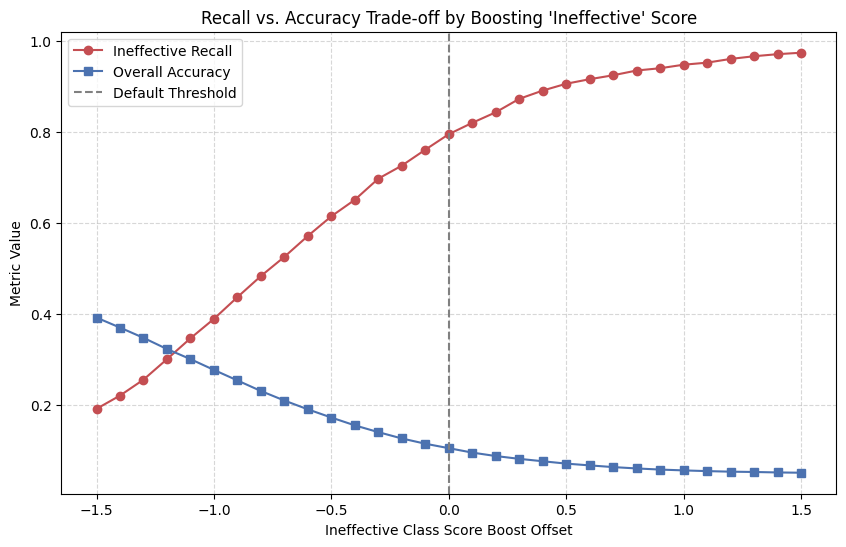

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, recall_score, accuracy_score

# 1. Extract the best final model (tuned_linear_svm_C0_5)
best_svm_pipeline = final_model

# 2. Get the decision function scores on the validation set
# LinearSVC outputs a raw distance score for each class.
decision_scores = best_svm_pipeline.decision_function(x_validation)

# Map our labels back to their index in LABEL_ORDER
ineffective_idx = LABEL_ORDER.index("Ineffective")

# Let's sweep potential bias/boost threshold offsets for the 'Ineffective' class score
threshold_offsets = np.linspace(-1.5, 1.5, 31)
recalls = []
accuracies = []
macro_f1s = []

for offset in threshold_offsets:
    temp_scores = decision_scores.copy()
    # Apply a boost to the raw score of the Ineffective class
    temp_scores[:, ineffective_idx] += offset

    # Predict the class with the highest modified score
    temp_preds_idx = np.argmax(temp_scores, axis=1)
    temp_preds = np.array([LABEL_ORDER[i] for i in temp_preds_idx])

    # Evaluate metrics on validation set
    rec = recall_score(y_validation, temp_preds, labels=LABEL_ORDER, average=None, zero_division=0)[ineffective_idx]
    acc = accuracy_score(y_validation, temp_preds)

    # Store results
    recalls.append(rec)
    accuracies.append(acc)

# Create a Sweep DataFrame for easy analysis
sweep_df = pd.DataFrame({
    'Ineffective_Score_Boost': threshold_offsets,
    'Ineffective_Recall': recalls,
    'Overall_Accuracy': accuracies
})

display(sweep_df.round(4))

# Plot the trade-off curve
if plt is not None:
    plt.figure(figsize=(10, 6))
    plt.plot(sweep_df['Ineffective_Score_Boost'], sweep_df['Ineffective_Recall'], label='Ineffective Recall', marker='o', color='#c44e52')
    plt.plot(sweep_df['Ineffective_Score_Boost'], sweep_df['Overall_Accuracy'], label='Overall Accuracy', marker='s', color='#4c72b0')
    plt.axvline(x=0, color='gray', linestyle='--', label='Default Threshold')
    plt.title("Recall vs. Accuracy Trade-off by Boosting 'Ineffective' Score")
    plt.xlabel("Ineffective Class Score Boost Offset")
    plt.ylabel("Metric Value")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()